In [1]:
!pip install textblob textstat

In [2]:
# Analysis	What it tells us
# Review length	Do longer reviews receive higher ratings?
# Sentiment	Are positive reviews associated with higher ratings?
# Readability	Are simple, easy-to-read reviews associated with ratings?
# Text characteristics	Which words and features appear in reviews with different ratings?

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from textblob import TextBlob
import textstat

In [4]:
data = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [5]:
data

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [6]:
data.shape

(23486, 11)

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


In [8]:
data.columns.tolist()

['Unnamed: 0',
 'Clothing ID',
 'Age',
 'Title',
 'Review Text',
 'Rating',
 'Recommended IND',
 'Positive Feedback Count',
 'Division Name',
 'Department Name',
 'Class Name']

Clean the review text

In [9]:
data = data.dropna(subset=['Rating'].copy())
data['Review Text'] = data['Review Text'].fillna('').astype(str)
data = data[data['Review Text'].str.strip()!=''].copy()
data.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


Calculate review length and verbosity

In [10]:
data['review_length'] = data['Review Text'].str.split().str.len()
data['character_count'] = data['Review Text'].str.len()
data[['Review Text','Rating','review_length','character_count']].head()

,Review Text,Rating,review_length,character_count
0,Absolutely wonderful - silky and sexy and comf...,4,8,53
1,Love this dress! it's sooo pretty. i happene...,5,62,303
2,I had such high hopes for this dress and reall...,3,98,500
3,"I love, love, love this jumpsuit. it's fun, fl...",5,22,124
4,This shirt is very flattering to all due to th...,5,36,192


Extract sentiment from reviews

In [11]:
data['sentiment'] = data['Review Text'].apply(
    lambda x: TextBlob(x).sentiment.polarity
)
data['sentiment_type'] = 'Neutral'
data.loc[data['sentiment'] > 0, 'sentiment_type'] = 'Positive'
data.loc[data['sentiment'] < 0, 'sentiment_type'] = 'Negative'

data[['Review Text','Rating','review_length','character_count']].head()

,Review Text,Rating,review_length,character_count
0,Absolutely wonderful - silky and sexy and comf...,4,8,53
1,Love this dress! it's sooo pretty. i happene...,5,62,303
2,I had such high hopes for this dress and reall...,3,98,500
3,"I love, love, love this jumpsuit. it's fun, fl...",5,22,124
4,This shirt is very flattering to all due to th...,5,36,192


In [12]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to C:\Users\Parmar
[nltk_data]     Trupti\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [13]:
from textblob import TextBlob

def sentiment_shift(review):
    sentences = TextBlob(str(review)).sentences
    scores = [s.sentiment.polarity for s in sentences]

    return max(scores) - min(scores) if scores else 0

data['sentiment_shift'] = data['Review Text'].apply(sentiment_shift)

data[['Review Text', 'sentiment_shift']].head()

,Review Text,sentiment_shift
0,Absolutely wonderful - silky and sexy and comf...,0.00000
1,Love this dress! it's sooo pretty. i happene...,0.62500
2,I had such high hopes for this dress and reall...,0.49871
3,"I love, love, love this jumpsuit. it's fun, fl...",0.60000
4,This shirt is very flattering to all due to th...,1.00000


Calculate readability scores

In [14]:
data['readability'] = data['Review Text'].apply(
    lambda x: textstat.flesch_reading_ease(x)
)

data[['Review Text', 'readability']].head()

,Review Text,readability
0,Absolutely wonderful - silky and sexy and comf...,-5.727143
1,Love this dress! it's sooo pretty. i happene...,89.914409
2,I had such high hopes for this dress and reall...,70.939235
3,"I love, love, love this jumpsuit. it's fun, fl...",80.182576
4,This shirt is very flattering to all due to th...,81.855000


Compare review length with ratings

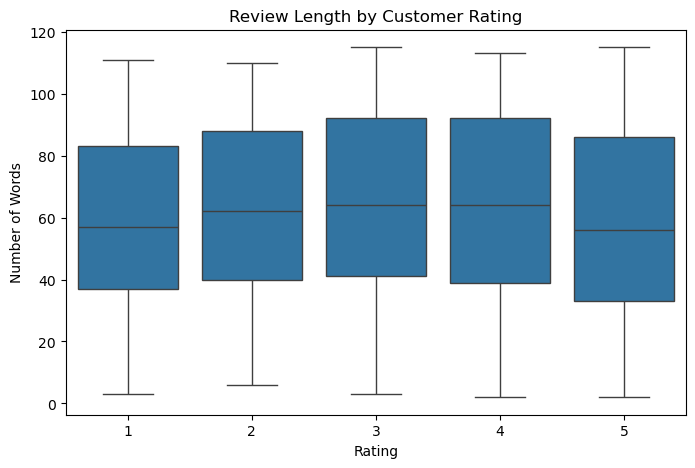

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x='Rating',
    y='review_length'
)

plt.title('Review Length by Customer Rating')
plt.xlabel('Rating')
plt.ylabel('Number of Words')
plt.show()

Compare sentiment with ratings

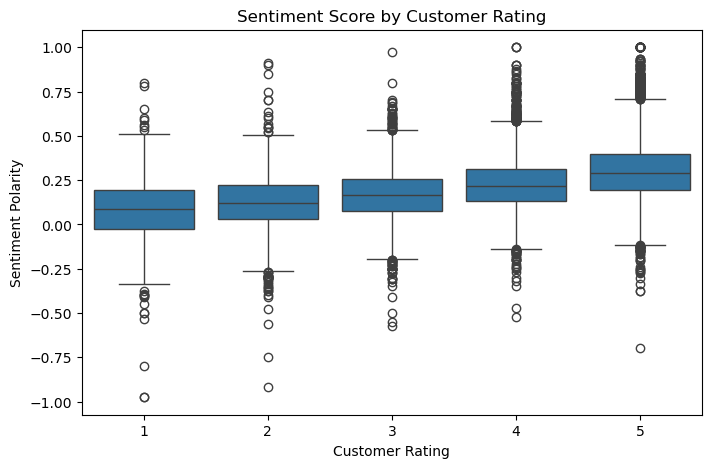

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x='Rating',
    y='sentiment'
)

plt.title('Sentiment Score by Customer Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Sentiment Polarity')
plt.show()

Compare readability with ratings

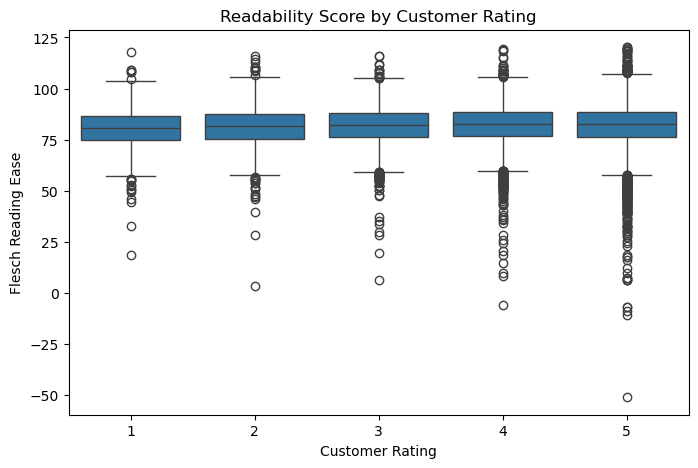

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x='Rating',
    y='readability'
)

plt.title('Readability Score by Customer Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Flesch Reading Ease')
plt.show()

Find correlations between text features and ratings

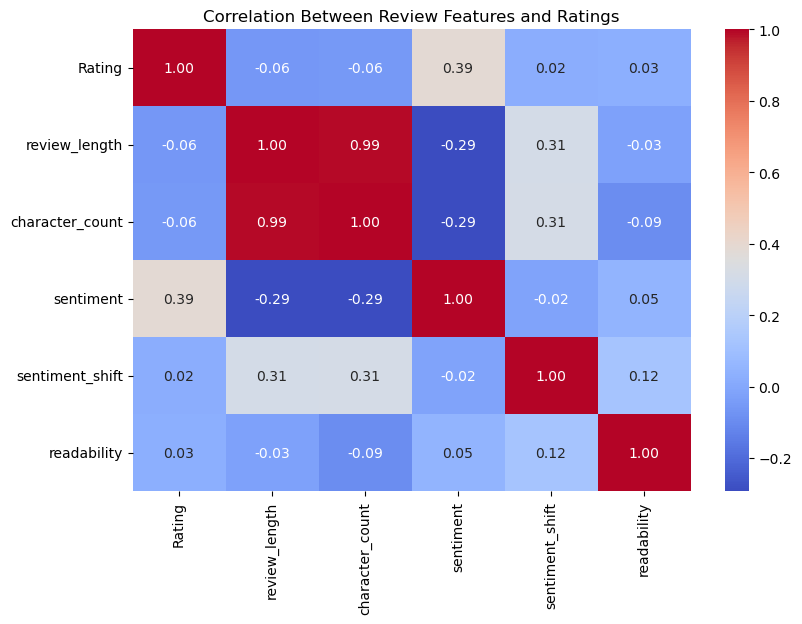

In [18]:
features = [
    'Rating',
    'review_length',
    'character_count',
    'sentiment',
    'sentiment_shift',
    'readability'
]

correlation = data[features].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Review Features and Ratings')
plt.show()

Display a simple summary table

In [19]:
summary = data.groupby('Rating').agg(
    Average_Review_Length=('review_length', 'mean'),
    Average_Sentiment=('sentiment', 'mean'),
    Average_Readability=('readability', 'mean'),
    Average_Sentiment_Shift=('sentiment_shift', 'mean')
).round(2)

print(summary)

        Average_Review_Length  Average_Sentiment  Average_Readability  \
Rating                                                                  
1                       58.63               0.08                80.24   
2                       62.06               0.12                81.27   
3                       64.22               0.17                81.77   
4                       63.32               0.23                82.08   
5                       57.94               0.30                81.99   

        Average_Sentiment_Shift  
Rating                           
1                          0.66  
2                          0.64  
3                          0.61  
4                          0.61  
5                          0.65  
